### Load 2D data file in SASView

run using global (Python 3.12.10) on PC fixe 

import all the packages

In [1]:
import numpy as np

import sasmodels
import sasmodels.core
import sasmodels.data
import sasmodels.bumps_model

import sasdata

from sasdata.dataloader.loader import Loader
from sasmodels.data import load_data
#from sas import sascalc.dataloader

from sasmodels.data import plot_theory

import bumps
import bumps.fitters
import bumps.names
import bumps.fitproblem

import os



In [2]:

"""
import matplotlib.pyplot and set custom default settings for plots
"""
%matplotlib inline
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')


import matplotlib.pyplot as plt
#from IPython.display import set_matplotlib_formats
#set_matplotlib_formats('svg')

plt.rc('font', size=14) # default fontsize
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=16)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=14)
plt.rc('legend', title_fontsize=14)
plt.rc('figure', titlesize=18)
plt.rc("figure", figsize=(5,5))
plt.rc("lines", linewidth=3)

#import tol_colors as tc # colorblind safe color palettes

# use colorblind safe colors:
#plt.rc('axes', prop_cycle=plt.cycler('color', list(tc.tol_cset('muted'))))
#try:
#    plt.cm.register_cmap('tc_iridescent', tc.tol_cmap('iridescent'))
#except:
#    pass

#plt.rc('image', cmap='tc_iridescent')

#plt.rc('image', cmap='rainbow')
plt.rc('image', cmap='jet')



### file selection

* This version works for a 2D data file already reduced in terms of number of data points
* (see beginning of prism-2D.ipynb for this part)

isotropic phase under E field SWING data
* .dat file obtained from SAXSProcessor by Nicolas

In [3]:
filename="./2D-data-examples/114V_234_red.dat"



### data loader method

In [4]:

data2d=sasmodels.data.load_data(filename)

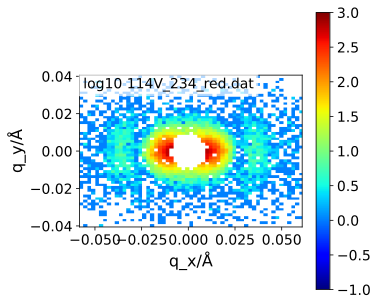

In [5]:
sasmodels.data.plot_data(data2d,view='log',limits=[0.1,1000])

#limits in intensity.

### fiting of the reduced set of data points in the image

In [6]:
sld_gold=125
sld_silver=77.9
sld_water=9.47
sld_toluene=8.4

### elliptical cylinder model

In [7]:
kernel = sasmodels.core.load_model("elliptical_cylinder")
params = {} # default parameters for now, parameters...
model = sasmodels.bumps_model.Model(kernel, **params)
experiment = sasmodels.bumps_model.Experiment(data=data2d, model=model)
#experiment = sasmodels.bumps_model.Experiment(data=data_reduced_ROI, model=model)

<Figure size 1000x500 with 0 Axes>

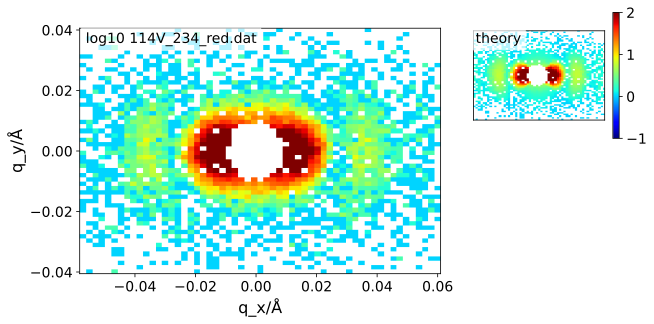

In [10]:
params = {
    "phi": 90, "theta": 90, "psi": 0,

    "theta_pd_type": 'gaussian', #polydispersity function
    "theta_pd": 17, #polydispersity
    "theta_pd_n": 100, #number of steps in polydispersity
    "theta_pd_nsigma": 3, #range of polydispersity

#    "phi_pd_type": 'uniform', #polydispersity function
#    "phi_pd": 90, #polydispersity
#    "phi_pd_n": 100, #number of steps in polydispersity

    "phi_pd_type": 'gaussian', #polydispersity function
    "phi_pd": 17, #polydispersity
    "phi_pd_n": 100, #number of steps in polydispersity
    "phi_pd_nsigma": 3, #range of polydispersity

#   "psi_pd_type": 'uniform', #polydispersity function
#    "psi_pd": 90, #polydispersity
#    "psi_pd_n": 20, #number of steps in polydispersity


    "axis_ratio": 1, # ratio for the elliptic crosssection, here for a cylinder 

    "radius_minor": 141, #radius of the NRs
    "radius_minor_pd_type": 'gaussian', #number of steps in polydispersity
    "radius_minor_pd": 0.06, #polydispersity
    "radius_minor_pd_n": 8, #number of steps in polydispersity
    "radius_minor_pd_nsigma": 4, #range of polydispersity

    "length":10000,

    "background": 1,
    "scale": 0.02
}
model = sasmodels.bumps_model.Model(model=kernel, **params)
experiment = sasmodels.bumps_model.Experiment(data=data2d, model=model)

plt.figure(figsize=(10,5))



model = sasmodels.bumps_model.Model(model=kernel, **params)

#list of the fiting parameters with their fiting range
model.scale.range(0.005,0.1)
model.background.range(0.01,10)
#model.theta_pd.range(15,20)
model.phi_pd.range(15,20)
model.theta_pd=model.phi_pd

#model.phi.range(70,120)
#model.theta.range(70,150)

#model.phi_pd.range(5, 10)
#model.theta_pd.range(5, 10)

#model.length.range(5000,20000)

#model.radius_minor.range(100,200)
#model.radius_pd.range(0.,0.1)

experiment = sasmodels.bumps_model.Experiment(data=data2d, model=model)

plt.figure(figsize=(10,5))
#experiment.plot()
plot_theory(data2d,experiment.theory(),view="log",limits=[0.1,100])

step 1 cost 163.0860(10)
                              background |.........          1 in [0.01, 10]
                                  phi_pd ...|......         17 in [15, 20]
                                   scale .|........       0.02 in [0.005, 0.1]
step 2 cost 99.8726(10)
step 3 cost 99.2214(10)
                              background |.........   0.897469 in [0.01, 10]
                                  phi_pd ....|.....    17.2295 in [15, 20]
                                   scale |.........  0.0101064 in [0.005, 0.1]
step 4 cost 98.7352(10)
step 4 cost 98.5773(10) [final]
                              background |.........   0.891759 in [0.01, 10]
                                  phi_pd ....|.....    17.4566 in [15, 20]
                                   scale |.........  0.0103094 in [0.005, 0.1]
time 1.2 minutes
final chisq 98.5773(10)
=== Uncertainty from curvature:     name   value(unc.) ===
                              background   0.8918(15)     
                   

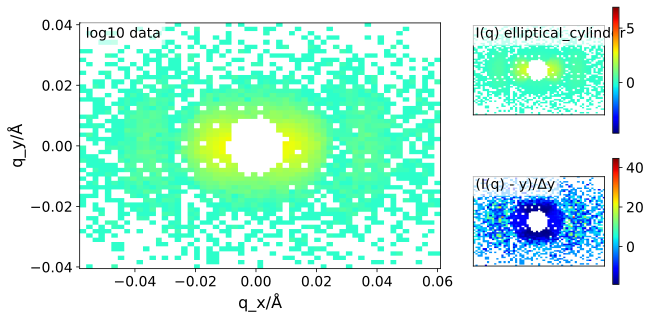

In [15]:
problem = bumps.fitproblem.FitProblem(experiment)

results = bumps.fitters.fit(problem, method='lm',steps=5, ftol=1.5e-08, xtol=1.5e-08, verbose=True)

plt.figure(figsize=(10, 5))
experiment.plot()

### prism model with orientation supported

In [11]:
kernel = sasmodels.core.load_model("prism")
params = {} # default parameters for now, parameters...
model = sasmodels.bumps_model.Model(kernel, **params)
experiment = sasmodels.bumps_model.Experiment(data=data2d, model=model)


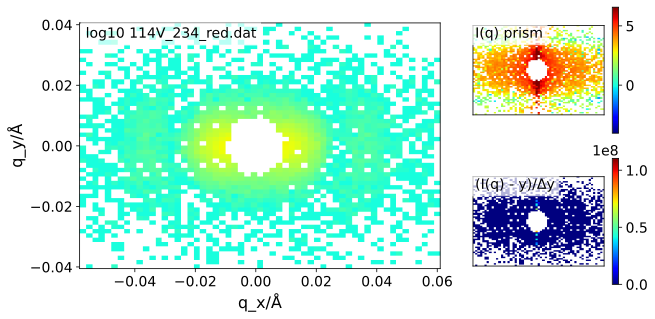

In [13]:
params = {
       "phi": 90, "theta": 90, "psi": 0,
    
    #    "theta_pd_type": 'gaussian', #polydispersity function
    #    "theta_pd": 17, #polydispersity
    #    "theta_pd_n": 100, #number of steps in polydispersity
    #    "theta_pd_nsigma": 3, #range of polydispersity
        
    #    "phi_pd_type": 'gaussian', #polydispersity function
    #    "phi_pd": 17, #polydispersity
    #    "phi_pd_n": 100, #number of steps in polydispersity
    #    "phi_pd_nsigma": 3, #range of polydispersity
    
    #   "psi_pd_type": 'uniform', #polydispersity function
    #    "psi_pd": 36, #polydispersity
    #    "psi_pd_n": 20, #number of steps in polydispersity
    
    "n_sides": 5,
    "radius_average": 140,
    "radius_average_pd_type": 'gaussian', 
    "radius_average_pd": 0.01, 
    "radius_average_pd_n": 8, 
    "radius_average_pd_nsigma": 3,
    "length": 10000,
    #"length_pd_type": 'gaussian', 
    #"length_pd": 0.05, 
    #"length_pd_n": 8, 
    #"length_pd_nsigma": 3,
    

    "sld": sld_gold,         
    "sld_solvent": sld_water,

    "background": 0.1,
    "scale": 1
}

model = sasmodels.bumps_model.Model(model=kernel, **params)
experiment = sasmodels.bumps_model.Experiment(data=data2d, model=model)

plt.figure(figsize=(10,5))

experiment.plot()